<a href="https://colab.research.google.com/github/oliviadellaglio/ds2002-walmart-midterm/blob/main/notebook/FINAL_Walmart_Midterm_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Inputting Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
import time
import os

landfall = pd.Timestamp("2024-09-26")

import subprocess
from pathlib import Path

repo_path = Path("/content/ds2002-walmart-midterm")

if not repo_path.exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/oliviadellaglio/ds2002-walmart-midterm.git",
            str(repo_path)
        ],
        check=True
    )

# Load the original transactions
df = pd.read_csv(
    repo_path / "data" / "walmart_transactions.csv"
)

print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))

display(df.head())

Number of rows: 25562
Number of columns: 8


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
0,TXN012636,FL-710,2024-09-13T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15
1,TXN000759,fl-412,2024-09-02 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02
2,TXN003338,FL-105,2024-09-06 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47
3,TXN025020,FL-330,2024-09-30 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59
4,TXN015797,FL-302,2024-09-15 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82


##Data Exploration

In [2]:
def profile(df, name="dataset"):

  # Show the size of the data
    print(f"=== {name} ===")
    print(f"{len(df):,} rows x {len(df.columns)} columns")
    print()

# Build summary table with one row per colummn in dataset
    summary = pd.DataFrame({
        # Data type of each column
        "dtype": df.dtypes.astype(str),
         # Count of missing (null/NaN) values
        "nulls": df.isnull().sum(),
        # Percent of each column that is missing, rounded to 1 decimal place
        "null_pct": (100 * df.isnull().mean()).round(1),
        # Number of unique values in each column
        "distinct": df.nunique()
    })

    display(summary)

    print("Exact duplicate rows:", df.duplicated().sum())

    return summary


profile(df, "Walmart Transactions")

=== Walmart Transactions ===
25,562 rows x 8 columns



,dtype,nulls,null_pct,distinct
transaction_id,object,0,0.0,25532
store_id,object,0,0.0,60
timestamp,object,886,3.5,23952
sku,object,0,0.0,45
product_name,object,0,0.0,63
category,object,0,0.0,37
quantity,int64,0,0.0,11
unit_price,object,0,0.0,3668


Exact duplicate rows: 30


,dtype,nulls,null_pct,distinct
transaction_id,object,0,0.0,25532
store_id,object,0,0.0,60
timestamp,object,886,3.5,23952
sku,object,0,0.0,45
product_name,object,0,0.0,63
category,object,0,0.0,37
quantity,int64,0,0.0,11
unit_price,object,0,0.0,3668


In [3]:
print("DATA TYPES:")
print(df.dtypes)

print("\nMISSING VALUES:")
print(df.isnull().sum())

print("\nDUPLICATE ROWS:")
print(df.duplicated().sum())

print("\nNUMBER OF UNIQUE VALUES:")
print(df.nunique())

print("\nSAMPLE SKU VALUES:")
print(df["sku"].value_counts().head(10))

print("\nSAMPLE QUANTITY VALUES:")
print(df["quantity"].astype(str).value_counts().head(10))

print("\nSAMPLE UNIT PRICES:")
print(df["unit_price"].value_counts().head(10))

print("\nEXAMPLES OF PRICES STORED AS TEXT:")
print(df["unit_price"].astype(str).head(20))

DATA TYPES:
transaction_id    object
store_id          object
timestamp         object
sku               object
product_name      object
category          object
quantity           int64
unit_price        object
dtype: object

MISSING VALUES:
transaction_id      0
store_id            0
timestamp         886
sku                 0
product_name        0
category            0
quantity            0
unit_price          0
dtype: int64

DUPLICATE ROWS:
30

NUMBER OF UNIQUE VALUES:
transaction_id    25532
store_id             60
timestamp         23952
sku                  45
product_name         63
category             37
quantity             11
unit_price         3668
dtype: int64

SAMPLE SKU VALUES:
sku
TARP-HD         766
LED-FLASH       732
FLASH-01        728
HDTARP-01       701
CHRG-PORT       684
CANDLE-EMRG     664
CNDL-EM         652
BEER-24         643
FIRSTAID-KIT    637
PORTCHARGER     632
Name: count, dtype: int64

SAMPLE QUANTITY VALUES:
quantity
1     10268
2      9290
3      37

Issues:

Duplicate transactions could inflate sales counts.
Missing timestamps could prevent transactions from being assigned to the correct date.
Inconsistent timestamp formats require standardized parsing.
Unit prices contain dollar signs and are stored as text.
Some quantities are negative or otherwise nonpositive.
Store IDs and product categories have inconsistent formatting.
Multiple SKUs can represent the same underlying product.

##Data Cleaning

In [4]:
def clean_transactions(df):
  # Work on a copy so the original raw data is never modified
    clean_df = df.copy()

  # Track the starting count
    print("Original rows:", len(clean_df))

  # Remove rows that are exact copies of another row
    clean_df = clean_df.drop_duplicates()
    print("After removing duplicates:", len(clean_df))

  # Convert unit_price to a number
    clean_df["unit_price"] = pd.to_numeric(
        clean_df["unit_price"].astype(str)
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False),
        errors="coerce"
    )

   # Convert quantity to a number; invalid entries become NaN
    clean_df["quantity"] = pd.to_numeric(
        clean_df["quantity"], errors="coerce"
    )

  # Keep only rows with a positive quantity (also drops NaN)
    clean_df = clean_df[clean_df["quantity"] > 0]
    print("After removing invalid quantities:", len(clean_df))


  # Convert timestamp text into real datetime values
    clean_df["timestamp"] = pd.to_datetime(
        clean_df["timestamp"],
        format="mixed",
        errors="coerce"
    )

  # Drop rows where the timestamp couldn't be parsed
    clean_df = clean_df.dropna(subset=["timestamp"])
    print("After removing missing timestamps:", len(clean_df))

  # Standardize store IDs
    clean_df["store_id"] = (
    clean_df["store_id"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.replace("_", "-", regex=False)
    .str.replace(r"^FL(?=\d{3}$)", "FL-", regex=True)
    )

  # Standardize category and SKU text
    for col in ["category", "sku"]:
        if col in clean_df.columns:
            clean_df[col] = (
                clean_df[col]
                .astype(str)
                .str.strip()
                .str.upper()
            )

  # Summary of the whole cleaning process
    print("Final cleaned rows:", len(clean_df))
    print("Total rows removed:", len(df) - len(clean_df))

    return clean_df


clean_df = clean_transactions(df)

display(clean_df.head())

Original rows: 25562
After removing duplicates: 25532
After removing invalid quantities: 25402
After removing missing timestamps: 24521
Final cleaned rows: 24521
Total rows removed: 1041


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
0,TXN012636,FL-710,2024-09-13 09:48:13,PNUTBTR-16,PEANUT BUTTER,GROCERY,1,3.15
1,TXN000759,FL-412,2024-09-02 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02
2,TXN003338,FL-105,2024-09-06 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,HOUSEHOLD ESSENTIALS,2,10.47
3,TXN025020,FL-330,2024-09-30 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59
4,TXN015797,FL-302,2024-09-15 15:59:42,BEER-24,Light Beer 24pk,ALCOHOLIC BEVERAGES,3,18.82


###Data Cleaning Validation

We validate the cleaned transactions by checking duplicate rows, missing timestamps, invalid quantities, price formatting, and standardized identifiers.

We also compare the cleaned dataset with the original transactions to document which records were excluded and ensure that cleaning decisions are reproducible.

In [5]:
# Validate the cleaned transactions
# Use the cleaning function directly so the results are independent
# of the later SKU mapping step.

validated_df = clean_transactions(df)

checks = {
    "No duplicate rows": validated_df.duplicated().sum() == 0,

    "No missing timestamps": validated_df["timestamp"].notna().all(),

    "Timestamps are datetime": pd.api.types.is_datetime64_any_dtype(
        validated_df["timestamp"]
    ),

    "Quantities are numeric": pd.api.types.is_numeric_dtype(
        validated_df["quantity"]
    ),

    "All quantities are positive": (
        validated_df["quantity"] > 0
    ).all(),

    "Prices are numeric": pd.api.types.is_numeric_dtype(
        validated_df["unit_price"]
    ),

    "Store IDs are standardized": (
        validated_df["store_id"]
        == validated_df["store_id"].str.strip().str.upper()
    ).all(),

    "SKUs are standardized": (
        validated_df["sku"]
        == validated_df["sku"].str.strip().str.upper()
    ).all(),

    "Categories are standardized": (
        validated_df["category"]
        == validated_df["category"].str.strip().str.upper()
    ).all()
}

validation_results = pd.DataFrame({
    "Check": list(checks.keys()),
    "Result": [
        "PASS" if passed else "FAIL"
        for passed in checks.values()
    ]
})

display(validation_results)

assert all(checks.values()), "One or more cleaning checks failed"

print("All core cleaning checks passed!")

Original rows: 25562
After removing duplicates: 25532
After removing invalid quantities: 25402
After removing missing timestamps: 24521
Final cleaned rows: 24521
Total rows removed: 1041


,Check,Result
0,No duplicate rows,PASS
1,No missing timestamps,PASS
2,Timestamps are datetime,PASS
3,Quantities are numeric,PASS
4,All quantities are positive,PASS
5,Prices are numeric,PASS
6,Store IDs are standardized,PASS
7,SKUs are standardized,PASS
8,Categories are standardized,PASS


All core cleaning checks passed!


In [6]:
# Check price quality after cleaning

price_checks = pd.DataFrame({
    "Issue": [
        "Missing prices",
        "Zero prices",
        "Negative prices",
        "Positive prices"
    ],
    "Number of rows": [
        validated_df["unit_price"].isna().sum(),
        (validated_df["unit_price"] == 0).sum(),
        (validated_df["unit_price"] < 0).sum(),
        (validated_df["unit_price"] > 0).sum()
    ]
})

display(price_checks)

# Inspect any questionable prices
problem_prices = validated_df[
    validated_df["unit_price"].isna()
    | (validated_df["unit_price"] <= 0)
]

display(problem_prices.head(20))

,Issue,Number of rows
0,Missing prices,0
1,Zero prices,0
2,Negative prices,0
3,Positive prices,24521


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price


In [7]:
# Reconstruct cleaning stages to verify the decision log

original_rows = len(df)

# Remove duplicate rows
step1 = df.drop_duplicates().copy()
duplicates_removed = original_rows - len(step1)

# Convert quantity to a number in a NEW column
step1["quantity_numeric"] = pd.to_numeric(
    step1["quantity"],
    errors="coerce"
)

# Keep only rows with a positive quantity
step2 = step1[step1["quantity_numeric"] > 0].copy()
invalid_quantities_removed = len(step1) - len(step2)

# Convert timestamp text to real datetimes in a NEW column
step2["parsed_timestamp"] = pd.to_datetime(
    step2["timestamp"],
    format="mixed",
    errors="coerce"
)

# Drop rows whose timestamp couldn't be parsed
step3 = step2.dropna(subset=["parsed_timestamp"]).copy()
invalid_timestamps_removed = len(step2) - len(step3)

# Build a summary table
removal_summary = pd.DataFrame({
    "Cleaning step": [
        "Original transactions",
        "Remove exact duplicates",
        "Remove invalid/nonpositive quantities",
        "Remove missing/invalid timestamps",
        "Final cleaned transactions"
    ],
    "Rows remaining": [
        original_rows,
        len(step1),
        len(step2),
        len(step3),
        len(validated_df)
    ],
    "Rows removed": [
        0,
        duplicates_removed,
        invalid_quantities_removed,
        invalid_timestamps_removed,
        0
    ]
})

display(removal_summary)

# The rebuilt pipeline should end with the same number of rows
# as the real cleaned dataset. If not, the assert stops the code with an error.
assert len(step3) == len(validated_df)

# The rows removed at each step should add up to the total rows removed
# overall
assert (
    duplicates_removed
    + invalid_quantities_removed
    + invalid_timestamps_removed
    == original_rows - len(validated_df)
)

print("Cleaning removal counts verified.")

,Cleaning step,Rows remaining,Rows removed
0,Original transactions,25562,0
1,Remove exact duplicates,25532,30
2,Remove invalid/nonpositive quantities,25402,130
3,Remove missing/invalid timestamps,24521,881
4,Final cleaned transactions,24521,0


Cleaning removal counts verified.


In [8]:
# Check remaining missing values and identifiers

print("Missing values in cleaned data:")
display(
    validated_df.isna().sum()
    .rename("Missing count")
    .to_frame()
)

print("\nBlank or placeholder identifiers:")

for col in ["store_id", "sku", "category"]:
    values = validated_df[col].astype(str).str.strip()

    invalid = values.isin(
        ["", "NAN", "NONE", "NULL", "<NA>"]
    )

    print(f"{col}: {invalid.sum()} suspicious values")

print("\nTransaction ID duplicates:")

if "transaction_id" in validated_df.columns:
    print(
        validated_df["transaction_id"].duplicated().sum(),
        "repeated transaction IDs"
    )
else:
    print("No transaction_id column found.")

Missing values in cleaned data:


,Missing count
transaction_id,0
store_id,0
timestamp,0
sku,0
product_name,0
category,0
quantity,0
unit_price,0



Blank or placeholder identifiers:
store_id: 0 suspicious values
sku: 0 suspicious values
category: 0 suspicious values

Transaction ID duplicates:
0 repeated transaction IDs


In [9]:
# Summarize the results

print("DATA CLEANING VALIDATION SUMMARY")
print("-" * 40)

print(f"Original rows: {len(df):,}")
print(f"Cleaned rows: {len(validated_df):,}")
print(f"Rows removed: {len(df) - len(validated_df):,}")

print(
    f"Percentage retained: "
    f"{100 * len(validated_df) / len(df):.2f}%"
)

print(
    f"Remaining duplicate rows: "
    f"{validated_df.duplicated().sum()}"
)

print(
    f"Remaining invalid quantities: "
    f"{(validated_df['quantity'] <= 0).sum()}"
)

print(
    f"Remaining missing timestamps: "
    f"{validated_df['timestamp'].isna().sum()}"
)

print(
    f"Remaining missing prices: "
    f"{validated_df['unit_price'].isna().sum()}"
)

DATA CLEANING VALIDATION SUMMARY
----------------------------------------
Original rows: 25,562
Cleaned rows: 24,521
Rows removed: 1,041
Percentage retained: 95.93%
Remaining duplicate rows: 0
Remaining invalid quantities: 0
Remaining missing timestamps: 0
Remaining missing prices: 0


###Cleaning Decision Log

In [10]:
decision_log = pd.DataFrame([
    {
        "Decision": "Remove duplicate rows",
        "Reason": "Prevent duplicate transactions from inflating sales counts.",
        "Rows removed": 30
    },
    {
        "Decision": "Convert unit_price to numeric",
        "Reason": "Allow accurate calculations of prices and revenue.",
        "Rows removed": 0
    },
    {
        "Decision": "Remove nonpositive quantities",
        "Reason": "Focus on positive purchases rather than returns or invalid quantities.",
        "Rows removed": 130
    },
    {
        "Decision": "Parse timestamps using mixed formats",
        "Reason": "Preserve valid timestamps recorded in different formats.",
        "Rows removed": 881
    },
    {
        "Decision": "Standardize store IDs",
        "Reason": "Make store IDs consistent for joining with store location data.",
        "Rows removed": 0
    },
    {
        "Decision": "Standardize SKU and category formatting",
        "Reason": "Make product identifiers and categories consistent.",
        "Rows removed": 0
    }
])

display(decision_log)

,Decision,Reason,Rows removed
0,Remove duplicate rows,Prevent duplicate transactions from inflating ...,30
1,Convert unit_price to numeric,Allow accurate calculations of prices and reve...,0
2,Remove nonpositive quantities,Focus on positive purchases rather than return...,130
3,Parse timestamps using mixed formats,Preserve valid timestamps recorded in differen...,881
4,Standardize store IDs,Make store IDs consistent for joining with sto...,0
5,Standardize SKU and category formatting,Make product identifiers and categories consis...,0


###Store Locations and Distribution Centers

In addition to transaction data, this project uses store-location and distribution-center reference files.

We standardize inconsistent identifiers and state abbreviations, resolve duplicate store records, flag missing coordinates, and convert distribution-center capacity values into numeric form.

We validate the resulting reference tables before using them in joins and geographic analysis.

In [11]:
# Get data and print raw values
stores_raw = pd.read_csv(
    repo_path / "data" / "store_locations.csv"
)

dc_raw = pd.read_csv(
    repo_path / "data" / "distribution_centers.csv"
)

print("STORE LOCATIONS")
display(stores_raw)

print("\nDISTRIBUTION CENTERS")
display(dc_raw)

STORE LOCATIONS


,store_id,store_name,city,state,zip_code,latitude,longitude,region
0,FL-239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central
1,FL-105,Walmart Supercenter Tampa,Tampa,FL,33602,27.9506,-82.4572,West
2,FL-330,Walmart Supercenter Miami,Miami,FL,33101,25.7617,-80.1918,South
3,FL-412,Walmart Supercenter Jacksonville,Jacksonville,FL,32099,30.3322,-81.6557,North
4,FL-287,Walmart Neighborhood Market Kissimmee,Kissimmee,Florida,34741,28.2920,-81.4076,Central
5,FL-156,Walmart Supercenter Daytona Beach,Daytona Beach,FL,32114,29.2108,-81.0228,East
6,FL-501,Walmart Supercenter Fort Myers,Fort Myers,FL,33901,26.6406,-81.8723,West
7,FL-078,Walmart Supercenter Gainesville,Gainesville,FL,32601,29.6516,-82.3248,North
8,FL-619,Walmart Supercenter Tallahassee,Tallahassee,FL,32301,NaN,NaN,Panhandle
9,FL-445,Walmart Supercenter St. Petersburg,St. Petersburg,Fla.,33701,27.7676,-82.6403,West



DISTRIBUTION CENTERS


,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment
0,DC-JAX,Jacksonville Distribution Center,Jacksonville,FL,500,1000,141,245.0
1,DC-ATL,Atlanta Distribution Center,Atlanta,GA,400,700,438,412.5
2,DC-DAL,Dallas Distribution Center,Dallas,TX,300,600,1108,687.0
3,DC-MIA,Miami Distribution Center,Miami,FL,350,~750,235,298.0
4,DC-BHM,Birmingham Distribution Center,Birmingham,AL,250,500,503,NaN


In [12]:
stores = stores_raw.copy()
# Work in a copy as to not alter original data

# Standardize store IDs
stores["store_id"] = (
    stores["store_id"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.replace("_", "-", regex=False)
    .str.replace(r"^FL(?=\d{3}$)", "FL-", regex=True)
)

# Standardize state abbreviations
stores["state"] = (
    stores["state"]
    .astype("string")
    .str.strip()
    .str.upper()
    .replace({
        "FLORIDA": "FL",
        "FLA.": "FL"
    })
)

# Convert coordinates to numeric
for col in ["latitude", "longitude"]:
    stores[col] = pd.to_numeric(
        stores[col],
        errors="coerce"
    )

# Check duplicate records before removing them
print("Duplicate store IDs after standardization:")
display(
    stores[
        stores.duplicated("store_id", keep=False)
    ].sort_values("store_id")
)

# Verify duplicate records agree on their locations
for store_id, group in stores.groupby("store_id"):
    if len(group) > 1:
        assert group["city"].nunique() == 1
        assert group["latitude"].nunique(dropna=True) <= 1
        assert group["longitude"].nunique(dropna=True) <= 1

# Keep one record per store
stores = stores.drop_duplicates(
    subset="store_id",
    keep="first"
).reset_index(drop=True)

print("\nUnique stores:", len(stores))

print("\nStores missing coordinates:")
display(
    stores[
        stores["latitude"].isna()
        | stores["longitude"].isna()
    ]
)

Duplicate store IDs after standardization:


,store_id,store_name,city,state,zip_code,latitude,longitude,region
0,FL-239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central
12,FL-239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central
4,FL-287,Walmart Neighborhood Market Kissimmee,Kissimmee,FL,34741,28.2920,-81.4076,Central
13,FL-287,Walmart Neighborhood Market Kissimmee,Kissimmee,FL,34741,28.2920,-81.4076,Central



Unique stores: 12

Stores missing coordinates:


,store_id,store_name,city,state,zip_code,latitude,longitude,region
8,FL-619,Walmart Supercenter Tallahassee,Tallahassee,FL,32301,NaN,NaN,Panhandle


#Question 1

Which product categories experienced the greatest sales surge in the 7 days before hurricane landfall compared to the prior baseline period? Quantify the percentage increase and visualize the daily trend for the top 5 categories.

Requires: Cleaning transaction data (deduplication, fixing SKUs, fixing timestamps), grouping by category, computing baseline vs. surge periods, line chart or bar chart.

In [13]:
# SKU consolidation from our October 30 submission

product_groups = {
    "STRAWBERRY_POP_TARTS": ["PT-12", "SKU#459812", "POPTART-STRAW", "PT_STRAWBERRY"],
    "BOTTLED_WATER": ["WTR-24", "WATER24PK", "WTR_24PK"],
    "AA_BATTERIES": ["BATT-100", "BAT-AA4", "BATT_AA_4PK"],
    "LED_FLASHLIGHT": ["FLASH-01", "LED-FLASH"],
    "LIGHT_BEER": ["BEER-24", "LTBEER24"],
    "MONOPOLY": ["BG-MONO", "MONOPOLY-01", "GAME-MONO"],
    "PLAYING_CARDS": ["CARDS-01", "PLAYCARD-STD"],
    "STREAMING_DEVICE": ["STREAM-01", "ROKU-STD"],
    "CANNED_SOUP": ["SOUP-CAN", "CNSOUP-01"],
    "WHITE_BREAD": ["BREAD-WH", "WHITEBREAD"],
    "PEANUT_BUTTER": ["PB-16", "PNUTBTR-16"],
    "EMERGENCY_CANDLES": ["CNDL-EM", "CANDLE-EMRG"],
    "FIRST_AID_KIT": ["FAID-01", "FIRSTAID-KIT"],
    "PORTABLE_CHARGER": ["CHRG-PORT", "PORTCHARGER"],
    "VARIETY_CHIPS": ["CHIPS-VP", "CHIPVARIETY"],
    "PAPER_TOWELS": ["PTOWEL-6", "PAPERTOWEL6"],
    "TOILET_PAPER": ["TP-12", "TOILETPAPER12"],
    "SIZE_3_DIAPERS": ["DIAP-S3", "DIAPERS-3"],
    "BABY_FORMULA": ["BFORM-01", "BABYFORMULA"],
    "HEAVY_DUTY_TARP": ["TARP-HD", "HDTARP-01"]
}

sku_mapping = pd.DataFrame([
    {"sku": sku, "canonical_product": product}
    for product, sku_list in product_groups.items()
    for sku in sku_list
])

catalog = pd.read_csv(repo_path / "data" / "product_catalog.csv")
catalog["sku"] = catalog["sku"].astype(str).str.strip().str.upper()

assert sku_mapping["sku"].is_unique
assert catalog["sku"].isin(sku_mapping["sku"]).all()

# Rebuild cleaned transactions to make this cell rerunnable
clean_df = clean_transactions(df)

rows_before = len(clean_df)
units_before = clean_df["quantity"].sum()

clean_df = clean_df.merge(
    sku_mapping,
    on="sku",
    how="left",
    validate="many_to_one"
)

assert clean_df["canonical_product"].notna().all()
assert len(clean_df) == rows_before
assert clean_df["quantity"].sum() == units_before

category_mapping = {
    "ALCOHOLIC BEVERAGES": "ALCOHOL",
    "BABY PRODUCTS": "BABY",
    "BREAKFAST FOODS": "BREAKFAST",
    "EMERGENCY SUPPLIES": "EMERGENCY",
    "GAMES & ENTERTAINMENT": "ENTERTAINMENT",
    "GROCERIES": "GROCERY",
    "HEALTH & WELLNESS": "HEALTH",
    "HOUSEHOLD ESSENTIALS": "HOUSEHOLD"
}

clean_df["category"] = clean_df["category"].replace(category_mapping)

assert len(clean_df) == rows_before
assert clean_df["quantity"].sum() == units_before

print("Cleaned transactions:", len(clean_df))
print("Original SKUs:", clean_df["sku"].nunique())
print("Canonical products:", clean_df["canonical_product"].nunique())
print("Categories:", clean_df["category"].nunique())

Original rows: 25562
After removing duplicates: 25532
After removing invalid quantities: 25402
After removing missing timestamps: 24521
Final cleaned rows: 24521
Total rows removed: 1041
Cleaned transactions: 24521
Original SKUs: 45
Canonical products: 20
Categories: 10


Baseline: September 1-8, 2024
Surge window: September 19-25, 2024
Landfall: September 26, 2024


,Baseline Avg Units/Day,Surge Avg Units/Day,Surge Multiple,Percentage Change
category,,,,
SNACKS,58.00,57.00,0.98,-1.72
BABY,90.62,83.57,0.92,-7.78
ALCOHOL,67.88,61.29,0.90,-9.71
HEALTH,49.25,44.43,0.90,-9.79
ELECTRONICS,79.88,71.43,0.89,-10.57
GROCERY,195.88,172.00,0.88,-12.19
ENTERTAINMENT,114.00,99.86,0.88,-12.41
HOUSEHOLD,101.00,85.43,0.85,-15.42
EMERGENCY,434.00,361.00,0.83,-16.82



Top five categories by percentage change:


,Baseline Avg Units/Day,Surge Avg Units/Day,Surge Multiple,Percentage Change
category,,,,
SNACKS,58.00,57.00,0.98,-1.72
BABY,90.62,83.57,0.92,-7.78
ALCOHOL,67.88,61.29,0.90,-9.71
HEALTH,49.25,44.43,0.90,-9.79
ELECTRONICS,79.88,71.43,0.89,-10.57



Baseline total: 1307.38 units/day
Pre-landfall total: 1107.43 units/day
Overall multiple: 0.85x
Overall percentage change: -15.29%


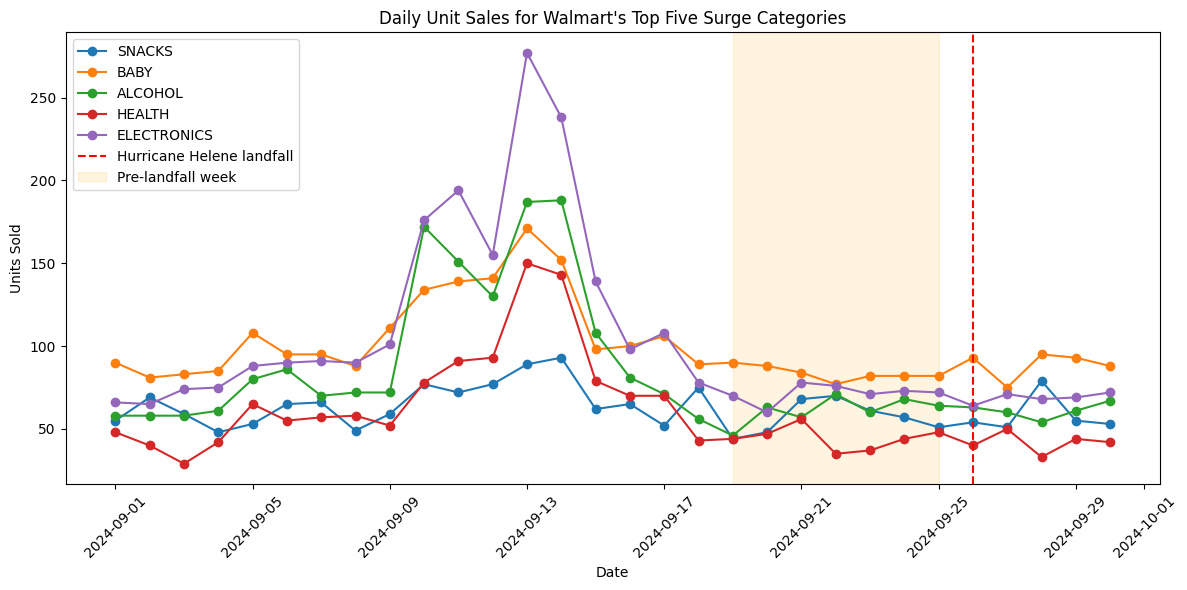

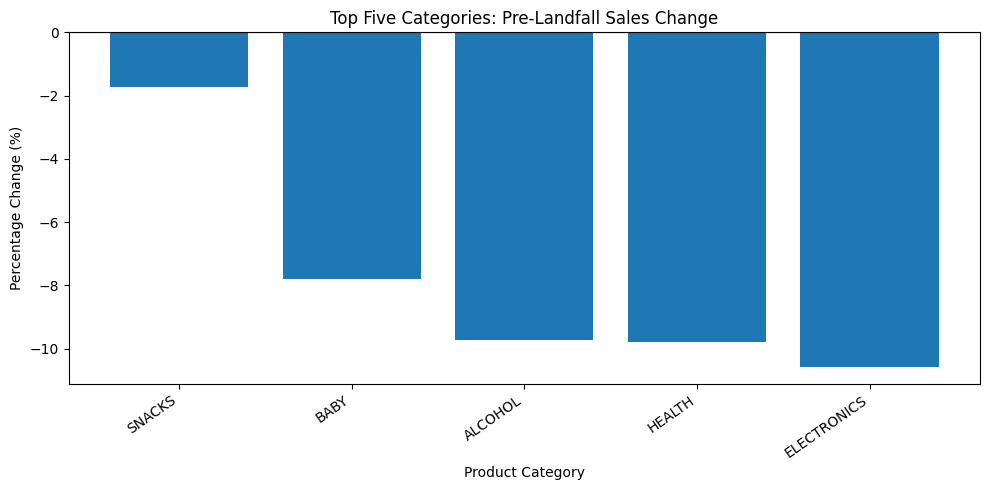

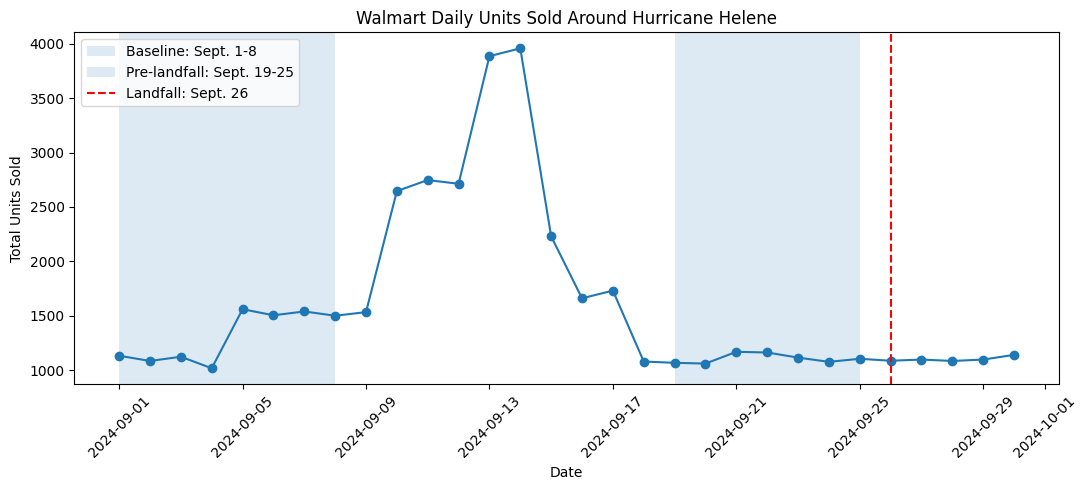

In [14]:
# Question 1: Demand Surge Identification

landfall = pd.Timestamp("2024-09-26")
baseline_start = pd.Timestamp("2024-09-01")
baseline_end = pd.Timestamp("2024-09-08")
surge_start = pd.Timestamp("2024-09-19")
surge_end = pd.Timestamp("2024-09-25")

q1_sales = clean_df.copy()
q1_sales["date"] = pd.to_datetime(
    q1_sales["timestamp"]
).dt.normalize()

# Daily sales by category
daily_categories = (
    q1_sales.groupby(["date", "category"])["quantity"]
    .sum()
    .unstack(fill_value=0)
    .reindex(
        pd.date_range("2024-09-01", "2024-09-30"),
        fill_value=0
    )
)

# Compare average daily sales
baseline_avg = daily_categories.loc[
    baseline_start:baseline_end
].mean()

surge_avg = daily_categories.loc[
    surge_start:surge_end
].mean()

q1_table = pd.DataFrame({
    "Baseline Avg Units/Day": baseline_avg,
    "Surge Avg Units/Day": surge_avg
})

q1_table["Surge Multiple"] = (
    q1_table["Surge Avg Units/Day"]
    / q1_table["Baseline Avg Units/Day"].replace(0, np.nan)
)

q1_table["Percentage Change"] = (
    (q1_table["Surge Multiple"] - 1) * 100
)

q1_table = q1_table.sort_values(
    "Percentage Change", ascending=False
)

print("Baseline: September 1-8, 2024")
print("Surge window: September 19-25, 2024")
print("Landfall: September 26, 2024")

display(q1_table.round(2))

# Top five categories by percentage change
top5 = q1_table.head(5).index

print("\nTop five categories by percentage change:")
display(q1_table.head(5).round(2))

# Overall sales comparison
total_baseline = baseline_avg.sum()
total_surge = surge_avg.sum()

print(f"\nBaseline total: {total_baseline:.2f} units/day")
print(f"Pre-landfall total: {total_surge:.2f} units/day")
print(f"Overall multiple: {total_surge / total_baseline:.2f}x")
print(
    f"Overall percentage change: "
    f"{(total_surge / total_baseline - 1) * 100:.2f}%"
)

# Graph 1: Daily trend for top five categories
plt.figure(figsize=(12, 6))

for category in top5:
    plt.plot(
        daily_categories.index,
        daily_categories[category],
        marker="o",
        label=category
    )

plt.axvline(
    landfall,
    color="red",
    linestyle="--",
    label="Hurricane Helene landfall"
)

plt.axvspan(
    surge_start,
    surge_end,
    color="orange",
    alpha=0.12,
    label="Pre-landfall week"
)

plt.title("Daily Unit Sales for Walmart's Top Five Surge Categories")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

# Graph 2: Percentage change by category
plt.figure(figsize=(10, 5))

plt.bar(
    q1_table.head(5).index,
    q1_table.head(5)["Percentage Change"]
)

plt.axhline(0, color="black", linewidth=0.8)
plt.title("Top Five Categories: Pre-Landfall Sales Change")
plt.xlabel("Product Category")
plt.ylabel("Percentage Change (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Graph 3: Overall daily sales
total_daily = daily_categories.sum(axis=1)

plt.figure(figsize=(11, 5))
plt.plot(total_daily.index, total_daily.values, marker="o")

plt.axvspan(
    baseline_start, baseline_end,
    alpha=0.15, label="Baseline: Sept. 1-8"
)

plt.axvspan(
    surge_start, surge_end,
    alpha=0.15, label="Pre-landfall: Sept. 19-25"
)

plt.axvline(
    landfall, color="red", linestyle="--",
    label="Landfall: Sept. 26"
)

plt.title("Walmart Daily Units Sold Around Hurricane Helene")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()


 Actual Helene landfall (Sept 26)
Overall baseline: 1307.38
Overall comparison: 1107.43
Overall percent change: -15.29


,Baseline Units/Day,Comparison Units/Day,Percent Change
category,,,
SNACKS,58.00,57.00,-1.72
BABY,90.62,83.57,-7.78
ALCOHOL,67.88,61.29,-9.71
HEALTH,49.25,44.43,-9.79
ELECTRONICS,79.88,71.43,-10.57
GROCERY,195.88,172.00,-12.19
ENTERTAINMENT,114.00,99.86,-12.41
HOUSEHOLD,101.00,85.43,-15.42
EMERGENCY,434.00,361.00,-16.82


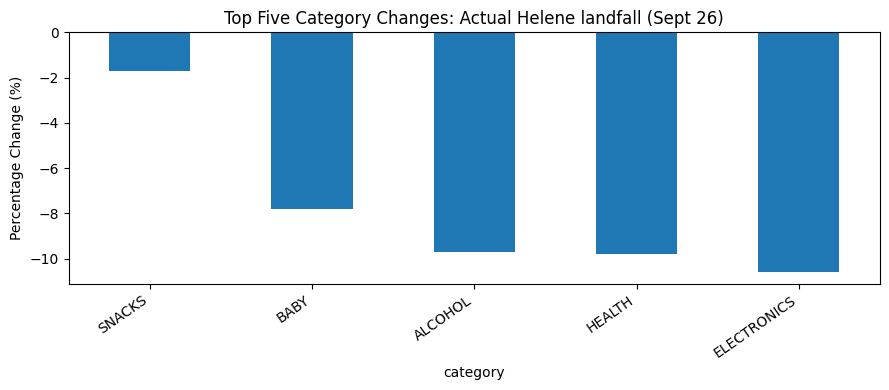


 Observed sales surge (Sept 13-14)
Overall baseline: 1089.0
Overall comparison: 2366.29
Overall percent change: 117.29


,Baseline Units/Day,Comparison Units/Day,Percent Change
category,,,
BREAKFAST,71.50,305.29,326.97
EMERGENCY,352.00,875.14,148.62
ELECTRONICS,70.00,154.86,121.22
ENTERTAINMENT,91.75,197.14,114.87
HEALTH,39.75,82.71,108.09
ALCOHOL,58.75,122.00,107.66
HOUSEHOLD,86.50,154.14,78.20
GROCERY,176.25,279.57,58.62
BABY,84.75,125.57,48.17


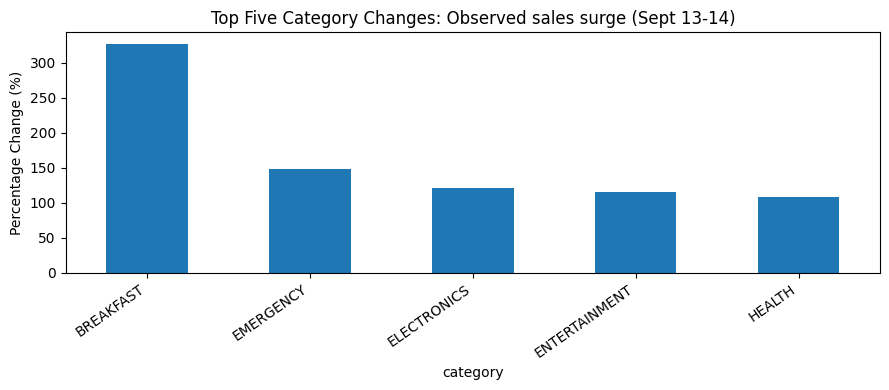

In [15]:
# Additional analysis: Actual landfall vs. observed sales surge

windows = {
    "Actual Helene landfall (Sept 26)": (
        "2024-09-01", "2024-09-08",
        "2024-09-19", "2024-09-25"
    ),
    "Observed sales surge (Sept 13-14)": (
        "2024-09-01", "2024-09-04",
        "2024-09-07", "2024-09-13"
    )
}

daily = (
    clean_df.assign(
        date=pd.to_datetime(clean_df["timestamp"]).dt.normalize()
    )
    .groupby(["date", "category"])["quantity"]
    .sum()
    .unstack(fill_value=0)
    .reindex(
        pd.date_range("2024-09-01", "2024-09-30"),
        fill_value=0
    )
)

for name, (b_start, b_end, s_start, s_end) in windows.items():

    baseline = daily.loc[b_start:b_end].mean()
    surge = daily.loc[s_start:s_end].mean()

    result = pd.DataFrame({
        "Baseline Units/Day": baseline,
        "Comparison Units/Day": surge
    })

    result["Percent Change"] = (
        (surge / baseline.replace(0, np.nan) - 1) * 100
    )

    result = result.sort_values(
        "Percent Change", ascending=False
    )

    print("\n", name)
    print("Overall baseline:", round(baseline.sum(), 2))
    print("Overall comparison:", round(surge.sum(), 2))
    print(
        "Overall percent change:",
        round((surge.sum() / baseline.sum() - 1) * 100, 2)
    )

    display(result.round(2))

    result["Percent Change"].head(5).plot(
        kind="bar",
        figsize=(9, 4),
        title=f"Top Five Category Changes: {name}"
    )

    plt.ylabel("Percentage Change (%)")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

### Comparing Actual Hurricane Landfall with the Observed Sales Surge

Our analysis identified an important difference between Hurricane Helene's actual landfall date and the purchasing patterns in our dataset. Hurricane Helene made landfall on September 26, 2024, but the largest sales increases occurred around September 13–14.

When comparing the seven days immediately preceding actual landfall (September 19–25) with the September 1–8 baseline, overall sales declined by approximately 15%. However, when examining the earlier surge period (September 7–13) against the September 1–4 baseline, sales increased by approximately 117%.

This difference demonstrates how the selection of comparison periods can significantly affect analytical conclusions. The earlier surge is visible in the sales data, but it does not coincide with Helene's actual landfall. Therefore, we analyzed both periods separately rather than treating the earlier sales spike as a direct response to Helene.

These findings emphasize the importance of validating event dates and selecting appropriate baseline periods when analyzing consumer behavior.

#Question 2

### Interpretation and Business Implications

After consolidating the four Strawberry Pop-Tarts SKU variants, we found that the product sold approximately 167 units per day on average, increasing to 305 units per day during the surge week and reaching a peak of 678 units on a single day.

Before consolidation, the product's demand appeared to be spread across four separate SKUs. The highest-selling individual SKU ranked only 8th among 45 SKUs, averaging approximately 40 units per day. However, after consolidation, Strawberry Pop-Tarts ranked 2nd among 20 products, behind bottled water.

This difference would significantly affect Walmart's inventory decisions. Using fragmented SKU data, Walmart might underestimate demand and fail to prioritize Strawberry Pop-Tarts when preparing for a hurricane. The consolidated data reveals substantially higher demand, suggesting that Walmart should increase its available inventory of this product ahead of anticipated purchasing surges.

SKU consolidation is therefore important not only for data accuracy but also for inventory forecasting, replenishment planning, and preventing stockouts.

Original SKUs: 45
Canonical products: 20
Largest consolidated family: STRAWBERRY_POP_TARTS
Number of SKUs in family: 4

Before consolidation:


,Units Sold
sku,
POPTART-STRAW,1239
PT-12,1332
PT_STRAWBERRY,1230
SKU#459812,1204



After consolidation:
STRAWBERRY_POP_TARTS: 5005 units

Validation passed: total units preserved.


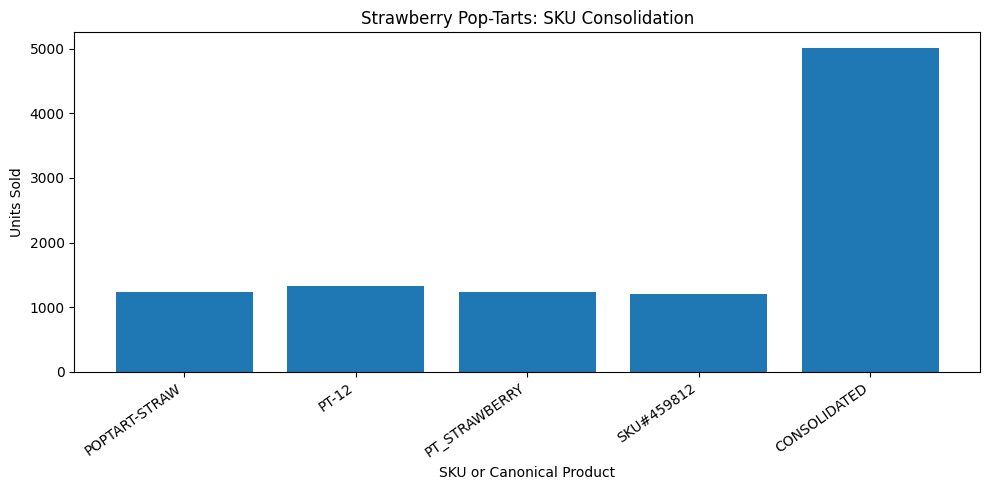

In [16]:
# Question 2: SKU Consolidation

original_skus = clean_df["sku"].nunique()
canonical_products = clean_df["canonical_product"].nunique()

family_sizes = (
    clean_df.groupby("canonical_product")["sku"]
    .nunique()
    .sort_values(ascending=False)
)

largest_family = family_sizes.index[0]
largest_family_size = family_sizes.iloc[0]

poptarts = clean_df[
    clean_df["canonical_product"] == "STRAWBERRY_POP_TARTS"
]

before = poptarts.groupby("sku")["quantity"].sum()
after = poptarts["quantity"].sum()

print("Original SKUs:", original_skus)
print("Canonical products:", canonical_products)
print("Largest consolidated family:", largest_family)
print("Number of SKUs in family:", largest_family_size)

print("\nBefore consolidation:")
display(before.to_frame("Units Sold"))

print("\nAfter consolidation:")
print("STRAWBERRY_POP_TARTS:", after, "units")

# Validate that consolidation preserves total units
assert before.sum() == after

assert (
    clean_df.groupby("sku")["quantity"].sum().sum()
    == clean_df.groupby("canonical_product")["quantity"].sum().sum()
)

print("\nValidation passed: total units preserved.")

# Visualize before and after consolidation
labels = list(before.index) + ["CONSOLIDATED"]
values = list(before.values) + [after]

plt.figure(figsize=(10, 5))
plt.bar(labels, values)
plt.title("Strawberry Pop-Tarts: SKU Consolidation")
plt.xlabel("SKU or Canonical Product")
plt.ylabel("Units Sold")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

Total Pop-Tarts sold: 5,005
Average daily sales: 166.83 units
Surge-week daily average: 305.29 units
Peak day: 2024-09-14
Peak daily sales: 678 units

Largest individual SKU: PT-12
Individual SKU average: 44.40 units/day
Individual SKU rank: 8 of 45
Consolidated product rank: 2 of 20

Largest SKU on product peak day: 240 units
All Pop-Tarts on peak day: 678 units


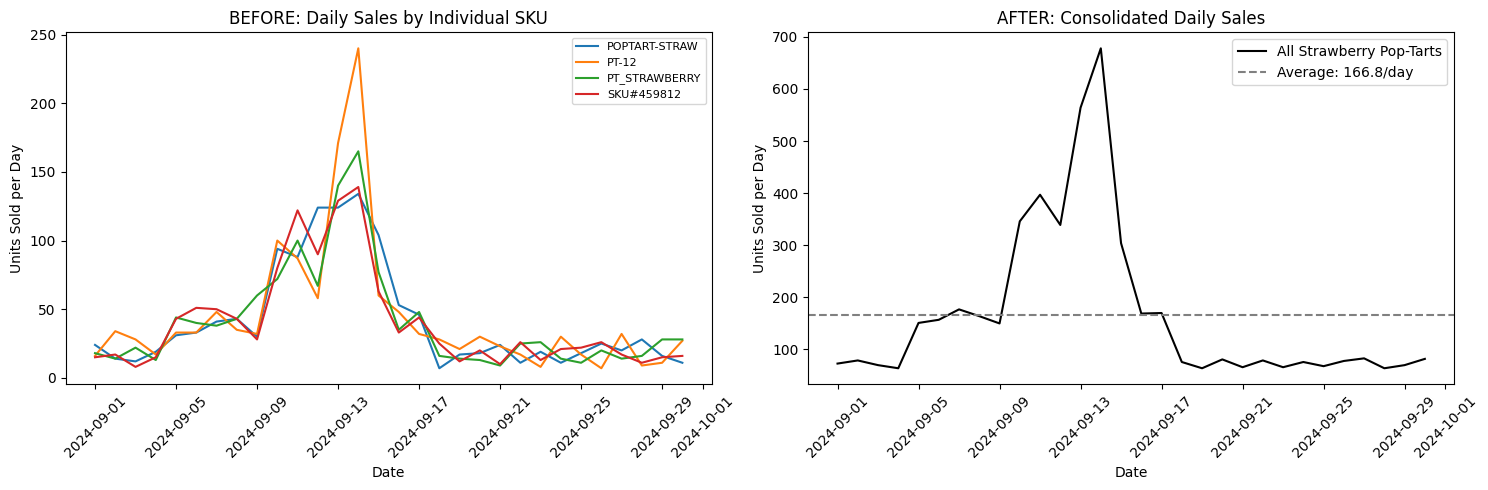

In [17]:
# Q2: True daily sales volume and SKU comparison

poptarts = clean_df[
    clean_df["canonical_product"] == "STRAWBERRY_POP_TARTS"
].copy()

poptarts["date"] = pd.to_datetime(
    poptarts["timestamp"]
).dt.normalize()

all_dates = pd.date_range("2024-09-01", "2024-09-30")

# Daily sales for each fragmented SKU
daily_sku = (
    poptarts.groupby(["date", "sku"])["quantity"]
    .sum()
    .unstack(fill_value=0)
    .reindex(all_dates, fill_value=0)
)

# Daily sales after consolidation
daily_product = daily_sku.sum(axis=1)

# Summary statistics
average_daily = daily_product.mean()
surge_week = daily_product.loc["2024-09-07":"2024-09-13"]
peak_day = daily_product.idxmax()
peak_units = daily_product.max()

print(f"Total Pop-Tarts sold: {daily_product.sum():,}")
print(f"Average daily sales: {average_daily:.2f} units")
print(f"Surge-week daily average: {surge_week.mean():.2f} units")
print(f"Peak day: {peak_day.date()}")
print(f"Peak daily sales: {peak_units:,} units")

# Compare product rankings before and after consolidation
sku_totals = clean_df.groupby("sku")["quantity"].sum()
product_totals = clean_df.groupby(
    "canonical_product"
)["quantity"].sum()

best_sku = poptarts.groupby("sku")["quantity"].sum().idxmax()
best_sku_total = sku_totals[best_sku]

sku_rank = sku_totals.rank(
    ascending=False, method="min"
)[best_sku]

product_rank = product_totals.rank(
    ascending=False, method="min"
)["STRAWBERRY_POP_TARTS"]

print(f"\nLargest individual SKU: {best_sku}")
print(f"Individual SKU average: {best_sku_total / 30:.2f} units/day")
print(f"Individual SKU rank: {int(sku_rank)} of {len(sku_totals)}")
print(f"Consolidated product rank: {int(product_rank)} of {len(product_totals)}")

# Compare peak-day SKU sales with the complete product
peak_sku_sales = daily_sku.loc[peak_day].max()

print(f"\nLargest SKU on product peak day: {peak_sku_sales:,} units")
print(f"All Pop-Tarts on peak day: {peak_units:,} units")

# Before-and-after line charts
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for sku in daily_sku.columns:
    axes[0].plot(
        daily_sku.index,
        daily_sku[sku],
        label=sku
    )

axes[0].set_title("BEFORE: Daily Sales by Individual SKU")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Units Sold per Day")
axes[0].legend(fontsize=8)
axes[0].tick_params(axis="x", rotation=45)

axes[1].plot(
    daily_product.index,
    daily_product.values,
    color="black",
    label="All Strawberry Pop-Tarts"
)

axes[1].axhline(
    average_daily,
    color="gray",
    linestyle="--",
    label=f"Average: {average_daily:.1f}/day"
)

axes[1].set_title("AFTER: Consolidated Daily Sales")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Units Sold per Day")
axes[1].legend()
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

#Question 3

### Comparing Correlation Methods

We analyzed the relationship between weather conditions and Walmart sales using both Pearson and Spearman correlations. The Pearson analysis examined total daily sales at the Tallahassee store, while the Spearman analysis examined daily sales separately across product categories.

The two methods measure different relationships. Pearson correlation measures linear relationships, while Spearman correlation measures monotonic relationships based on ranked values. Additionally, category-level sales patterns may differ from total store sales.

For example, the Pearson correlation between precipitation and total daily sales was approximately 0.04, indicating a very weak positive linear relationship. Different values in the category-level heatmap do not necessarily indicate an error because they represent different sales groupings and use a different correlation method.

These results suggest that the relationship between weather conditions and purchasing behavior depends on both the product category and the analytical method used.

In [18]:
# Question 3: Weather Correlation
# Historical weather data from Open-Meteo

BASE = "https://archive-api.open-meteo.com/v1/archive"

RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(
    start,
    end,
    lat=30.4383,
    lon=-84.2807,
    tries=3
):
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": start,
        "end_date": end,
        "daily": (
            "wind_gusts_10m_max,"
            "wind_speed_10m_max,"
            "precipitation_sum,"
            "pressure_msl_mean"
        ),
        "timezone": "America/New_York"
    }

    for attempt in range(1, tries + 1):
        try:
            r = requests.get(
                BASE,
                params=params,
                timeout=20
            )

            if r.status_code in RETRY_STATUSES:
                r.raise_for_status()

            r.raise_for_status()

            weather = pd.DataFrame(r.json()["daily"])

            weather = weather.rename(
                columns={"time": "date"}
            )

            weather["date"] = pd.to_datetime(
                weather["date"]
            )

            weather["source"] = "open-meteo"

            return weather

        except requests.RequestException:
            if attempt == tries:
                raise

            time.sleep(2 ** attempt)


# Retrieve September 2024 weather
try:
    weather = daily_weather(
        "2024-09-01",
        "2024-09-30"
    )

    print("Weather API call successful!")
    print("Source:", weather["source"].iloc[0])
    print("Number of days:", len(weather))

    display(weather.head())

except requests.RequestException as err:
    print("Weather API call failed:", err)
    raise

Weather API call successful!
Source: open-meteo
Number of days: 30


,date,wind_gusts_10m_max,wind_speed_10m_max,precipitation_sum,pressure_msl_mean,source
0,2024-09-01,25.9,9.4,0.0,1014.0,open-meteo
1,2024-09-02,28.8,12.0,0.0,1013.3,open-meteo
2,2024-09-03,41.8,18.7,3.3,1015.8,open-meteo
3,2024-09-04,47.9,21.3,0.0,1018.9,open-meteo
4,2024-09-05,42.8,19.2,0.3,1017.7,open-meteo


Store sales days before join: 30
Days after join: 30
Matched days: 30
Weather source: ['open-meteo']
Days available for correlation: 30
Weather correlations with daily units sold:


,Pearson Correlation
wind_speed_10m_max,-0.026468
wind_gusts_10m_max,-0.033420
precipitation_sum,0.043086
pressure_msl_mean,0.150237


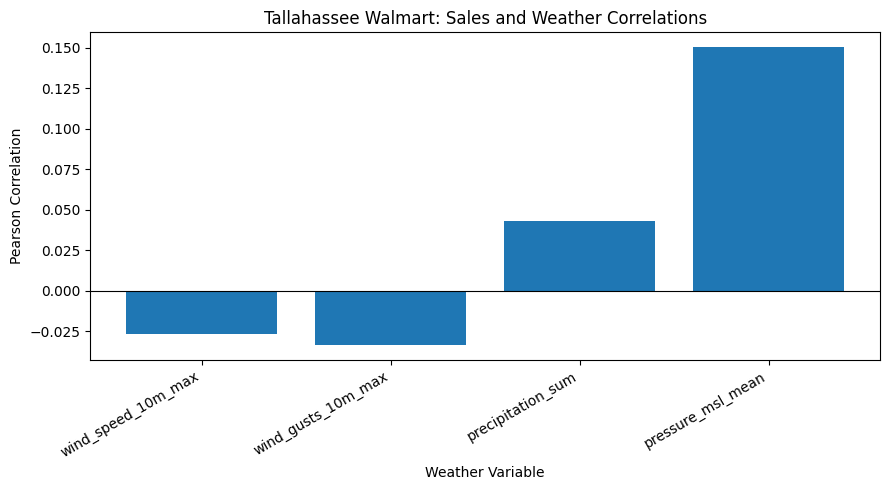

In [19]:
# Tallahassee Walmart store
store_id = "FL-619"

store_sales = clean_df[
    clean_df["store_id"] == store_id
].copy()

store_sales["date"] = (
    pd.to_datetime(store_sales["timestamp"]).dt.normalize()
)

# Calculate daily unit sales
daily_store_sales = (
    store_sales.groupby("date")["quantity"]
    .sum()
    .rename("units_sold")
    .reset_index()
)

# Join sales and weather data
q3_data = daily_store_sales.merge(
    weather,
    on="date",
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Store sales days before join:", len(daily_store_sales))
print("Days after join:", len(q3_data))
print("Matched days:", (q3_data["_merge"] == "both").sum())

# Validate that the join preserved all sales records
assert len(q3_data) == len(daily_store_sales), (
    "The join changed the number of sales days"
)

print("Weather source:", weather["source"].unique())

weather_columns = [
    "wind_speed_10m_max",
    "wind_gusts_10m_max",
    "precipitation_sum",
    "pressure_msl_mean"
]

q3_complete = q3_data.dropna(
    subset=["units_sold"] + weather_columns
)

print("Days available for correlation:", len(q3_complete))

# Calculate Pearson correlations
correlations = (
    q3_complete[["units_sold"] + weather_columns]
    .corr()["units_sold"]
    .drop("units_sold")
)

print("Weather correlations with daily units sold:")
display(correlations.to_frame("Pearson Correlation"))

# Visualize correlations
plt.figure(figsize=(9, 5))

plt.bar(correlations.index, correlations.values)
plt.axhline(0, color="black", linewidth=0.8)

plt.title("Tallahassee Walmart: Sales and Weather Correlations")
plt.xlabel("Weather Variable")
plt.ylabel("Pearson Correlation")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

,Weather Variable,Lag (days),Pearson Correlation,Days Used
0,wind_speed_10m_max,0,-0.026,30
1,wind_speed_10m_max,1,0.055,29
2,wind_speed_10m_max,2,0.072,28
3,wind_gusts_10m_max,0,-0.033,30
4,wind_gusts_10m_max,1,0.010,29
5,wind_gusts_10m_max,2,0.012,28
6,precipitation_sum,0,0.043,30
7,precipitation_sum,1,-0.025,29
8,precipitation_sum,2,-0.065,28
9,pressure_msl_mean,0,0.150,30


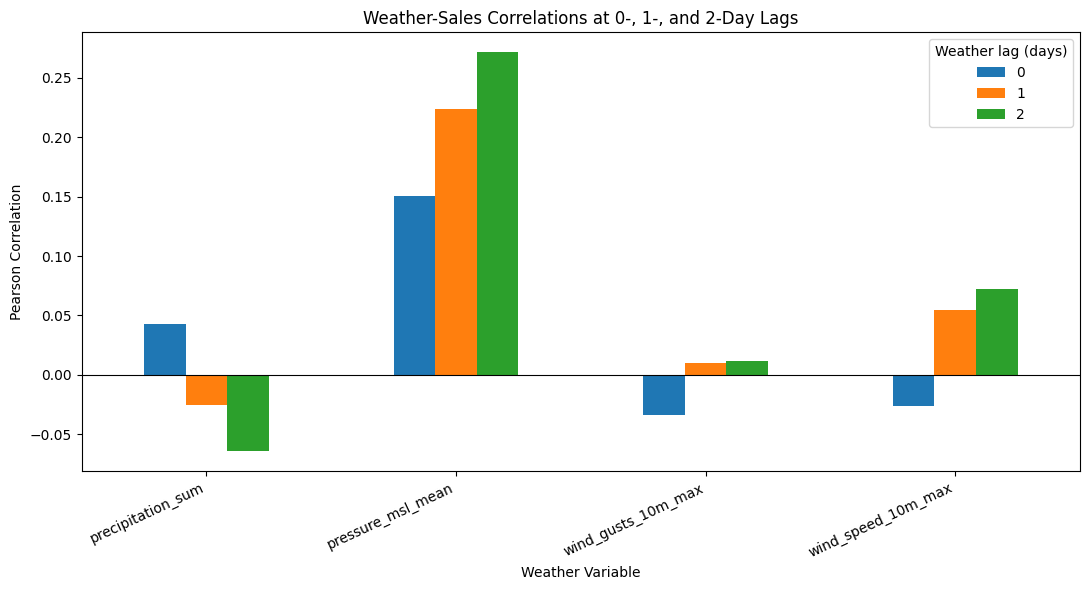

In [20]:
# Weather correlation with 0-, 1-, and 2-day lags

lag_data = q3_complete.copy().sort_values("date")

lag_data = lag_data.set_index("date").asfreq("D")

weather_variables = [
    "wind_speed_10m_max",
    "wind_gusts_10m_max",
    "precipitation_sum",
    "pressure_msl_mean"
]

results = []

for variable in weather_variables:
    for lag in [0, 1, 2]:

        earlier_weather = lag_data[variable].shift(lag)

        paired = pd.DataFrame({
            "sales": lag_data["units_sold"],
            "weather": earlier_weather
        }).dropna()

        correlation = paired["sales"].corr(paired["weather"])

        results.append({
            "Weather Variable": variable,
            "Lag (days)": lag,
            "Pearson Correlation": correlation,
            "Days Used": len(paired)
        })

lag_results = pd.DataFrame(results)

display(lag_results.round(3))

# Visualize lag correlations
lag_chart = lag_results.pivot(
    index="Weather Variable",
    columns="Lag (days)",
    values="Pearson Correlation"
)

lag_chart.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.axhline(0, color="black", linewidth=0.8)
plt.title("Weather-Sales Correlations at 0-, 1-, and 2-Day Lags")
plt.xlabel("Weather Variable")
plt.ylabel("Pearson Correlation")
plt.xticks(rotation=25, ha="right")
plt.legend(title="Weather lag (days)")
plt.tight_layout()
plt.show()

Spearman correlations by category:


,wind_speed_10m_max,wind_gusts_10m_max,precipitation_sum,pressure_msl_mean
category,,,,
ALCOHOL,0.18,0.16,0.19,0.23
BABY,0.47,0.27,0.17,-0.09
BREAKFAST,0.24,0.21,0.40,0.15
ELECTRONICS,0.14,0.08,0.20,0.38
EMERGENCY,0.20,0.16,0.41,0.28
ENTERTAINMENT,0.20,0.13,0.39,0.12
GROCERY,0.08,-0.06,0.20,0.23
HEALTH,0.22,0.07,0.25,0.12
HOUSEHOLD,0.14,0.11,0.24,0.17


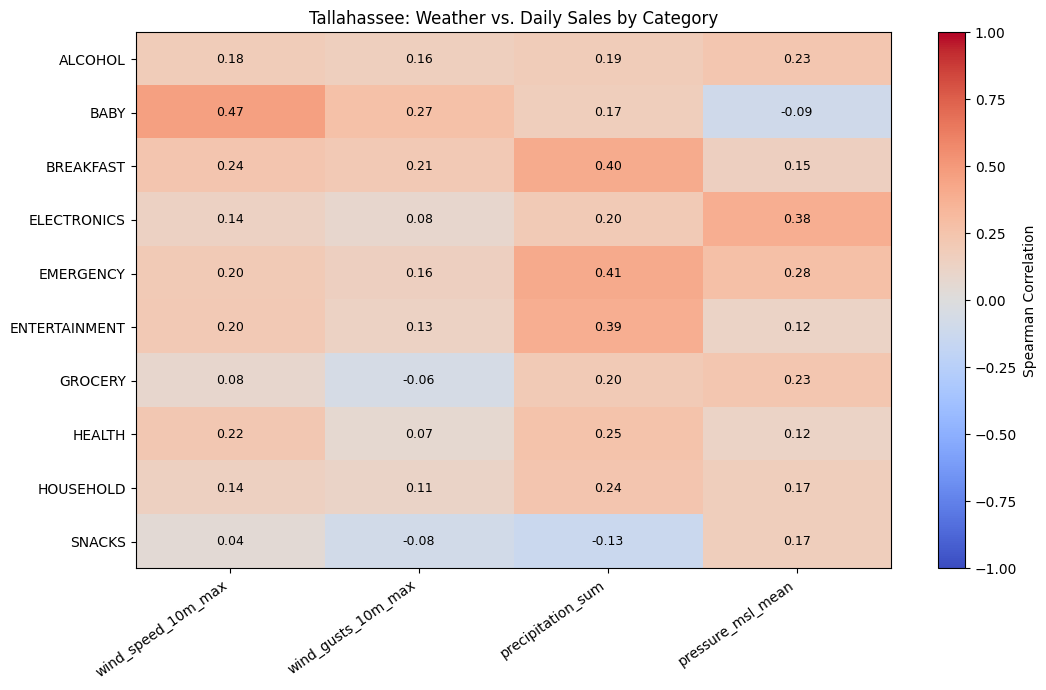

In [21]:
# Q3: Category-level weather correlation heatmap

# Use the same Tallahassee store as the Pearson analysis
category_sales = clean_df[
    clean_df["store_id"] == "FL-619"
].copy()

category_sales["date"] = pd.to_datetime(
    category_sales["timestamp"]
).dt.normalize()

# Daily sales by category
daily_category_sales = (
    category_sales.groupby(["date", "category"])["quantity"]
    .sum()
    .unstack(fill_value=0)
    .reindex(
        pd.date_range("2024-09-01", "2024-09-30"),
        fill_value=0
    )
)

# Join category sales with daily weather
category_weather = daily_category_sales.merge(
    weather.set_index("date")[weather_columns],
    left_index=True,
    right_index=True,
    how="inner"
)

# Calculate Spearman correlations by category
spearman_results = pd.DataFrame(
    index=daily_category_sales.columns,
    columns=weather_columns,
    dtype=float
)

for category in daily_category_sales.columns:
    for variable in weather_columns:
        spearman_results.loc[category, variable] = (
            category_weather[category].corr(
                category_weather[variable],
                method="spearman"
            )
        )

print("Spearman correlations by category:")
display(spearman_results.round(2))

# Heatmap
fig, ax = plt.subplots(figsize=(11, 7))

heatmap = ax.imshow(
    spearman_results.values.astype(float),
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(range(len(weather_columns)))
ax.set_xticklabels(weather_columns, rotation=35, ha="right")

ax.set_yticks(range(len(spearman_results.index)))
ax.set_yticklabels(spearman_results.index)

for i in range(len(spearman_results.index)):
    for j in range(len(weather_columns)):
        value = spearman_results.iloc[i, j]
        ax.text(
            j, i, f"{value:.2f}",
            ha="center", va="center",
            fontsize=9
        )

plt.colorbar(heatmap, ax=ax, label="Spearman Correlation")
plt.title(
    "Tallahassee: Weather vs. Daily Sales by Category"
)
plt.tight_layout()
plt.show()

In [22]:
# Q3: Compare Pearson and Spearman for the same sales data

comparison = pd.DataFrame({
    "Pearson": [
        q3_complete["units_sold"].corr(
            q3_complete[col], method="pearson"
        )
        for col in weather_columns
    ],
    "Spearman": [
        q3_complete["units_sold"].corr(
            q3_complete[col], method="spearman"
        )
        for col in weather_columns
    ]
}, index=weather_columns)

print("Tallahassee total daily sales:")
display(comparison.round(3))

# Check category-level Spearman correlations
n = len(category_weather)

# Approximate critical correlation for 5% significance
from scipy.stats import t

critical_t = t.ppf(0.975, df=n-2)
critical_r = np.sqrt(
    critical_t**2 / (critical_t**2 + n - 2)
)

print(f"\nApproximate significance threshold: ±{critical_r:.3f}")

significant_cells = (
    spearman_results.abs() > critical_r
)

print(
    "Category-weather correlations above threshold:",
    int(significant_cells.sum().sum())
)

display(spearman_results.round(3))

Tallahassee total daily sales:


,Pearson,Spearman
wind_speed_10m_max,-0.026,0.252
wind_gusts_10m_max,-0.033,0.140
precipitation_sum,0.043,0.321
pressure_msl_mean,0.150,0.329



Approximate significance threshold: ±0.361
Category-weather correlations above threshold: 5


,wind_speed_10m_max,wind_gusts_10m_max,precipitation_sum,pressure_msl_mean
category,,,,
ALCOHOL,0.181,0.161,0.185,0.227
BABY,0.468,0.267,0.167,-0.094
BREAKFAST,0.240,0.207,0.404,0.150
ELECTRONICS,0.140,0.079,0.199,0.383
EMERGENCY,0.201,0.155,0.408,0.276
ENTERTAINMENT,0.204,0.128,0.387,0.125
GROCERY,0.078,-0.058,0.200,0.232
HEALTH,0.222,0.069,0.254,0.122
HOUSEHOLD,0.142,0.111,0.240,0.171


### Question 3: Weather Correlation Conclusions

Our analysis examined whether wind speed, precipitation, and barometric pressure were associated with daily sales at the Tallahassee Walmart store.

We used Pearson correlations to examine linear relationships with total daily sales and Spearman correlations to examine ranked relationships across individual product categories. These methods can produce different results because they measure different relationships and use different levels of sales aggregation.

The lag analysis did not reveal a convincing relationship between worsening weather conditions and subsequent purchasing spikes. The strongest observed lagged correlation was approximately 0.27, which is relatively weak.

One limitation is that the largest sales spike occurred around September 13–14, while Hurricane Helene made landfall on September 26. The weather data therefore does not align with the observed purchasing surge.

Overall, we cannot conclude that worsening weather conditions directly caused the sales increases in this dataset. Additional data on weather forecasts, storm warnings, and consumer purchasing behavior would be needed to investigate that relationship more thoroughly.

#Question 4

In [23]:
store_sales = clean_df.copy()

store_sales["date"] = pd.to_datetime(
    store_sales["timestamp"]
).dt.normalize()

# Calculate total daily units sold at each store
daily_store = (
    store_sales
    .groupby(["store_id", "date"])["quantity"]
    .sum()
    .reset_index()
)

# Compare baseline and pre-landfall periods
baseline_store = (
    daily_store[
        daily_store["date"].between(
            "2024-09-01", "2024-09-08"
        )
    ]
    .groupby("store_id")["quantity"]
    .mean()
)

surge_store = (
    daily_store[
        daily_store["date"].between(
            "2024-09-19", "2024-09-25"
        )
    ]
    .groupby("store_id")["quantity"]
    .mean()
)

q4_results = pd.DataFrame({
    "Baseline Avg": baseline_store,
    "Pre-Landfall Avg": surge_store
})

q4_results["Percentage Change"] = (
    (q4_results["Pre-Landfall Avg"]
     / q4_results["Baseline Avg"] - 1) * 100
)

# Calculate absolute change in daily sales

q4_results["Absolute Change"] = (
    q4_results["Pre-Landfall Avg"]
    - q4_results["Baseline Avg"]
)

# Add store locations and regions

q4_results = q4_results.reset_index()
q4_results = q4_results.merge(
    stores[["store_id", "city", "region"]],
    on="store_id",
    how="left",
    validate="one_to_one"
)

# Display results sorted by percentage change

display(
    q4_results.sort_values(
        "Percentage Change", ascending=False
    ).round(2)
)

,store_id,Baseline Avg,Pre-Landfall Avg,Percentage Change,Absolute Change,city,region
2,FL-156,107.75,95.57,-11.30,-12.18,Daytona Beach,East
4,FL-287,110.62,97.57,-11.80,-13.05,Kissimmee,Central
11,FL-710,104.50,92.00,-11.96,-12.50,Pensacola,Panhandle
3,FL-239,104.25,91.14,-12.57,-13.11,Orlando,Central
7,FL-412,105.25,91.29,-13.27,-13.96,Jacksonville,North
9,FL-501,103.62,89.86,-13.29,-13.77,Fort Myers,West
1,FL-105,108.25,91.71,-15.28,-16.54,Tampa,West
8,FL-445,114.50,97.00,-15.28,-17.50,St. Petersburg,West
10,FL-619,107.62,89.14,-17.17,-18.48,Tallahassee,Panhandle
5,FL-302,114.88,93.57,-18.55,-21.30,Lakeland,Central


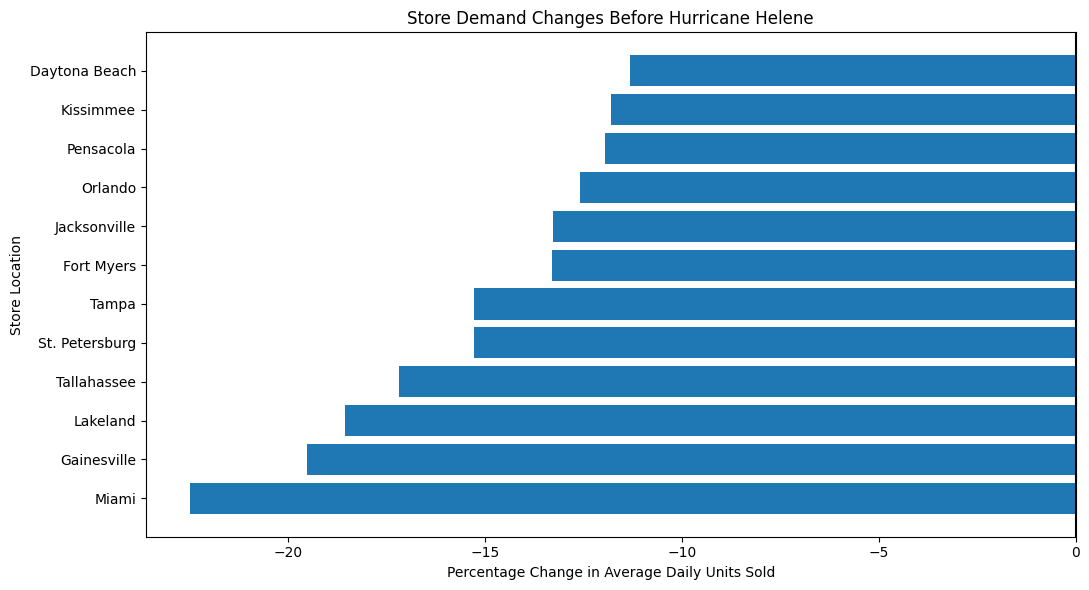

In [24]:
# Visualize percentage changes across stores

q4_sorted = q4_results.sort_values("Percentage Change")

plt.figure(figsize=(11, 6))

plt.barh(
    q4_sorted["city"],
    q4_sorted["Percentage Change"]
)

plt.xlabel("Percentage Change in Average Daily Units Sold")
plt.ylabel("Store Location")
plt.title("Store Demand Changes Before Hurricane Helene")

plt.axvline(0, color="black")
plt.tight_layout()
plt.show()

In [25]:
# Compare average percentage changes by region

q4_results["region"] = q4_results["region"].str.strip()
region_changes = (
    q4_results
    .groupby("region")["Percentage Change"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Percentage Change by Region:")
display(region_changes.round(2))

Average Percentage Change by Region:


,Percentage Change
region,
East,-11.30
Central,-14.31
Panhandle,-14.57
West,-14.62
North,-16.40
South,-22.48


,store_id,Baseline Avg,Comparison Avg,Surge Multiple,Percentage Change,Window,city,region
2,FL-156,107.75,95.57,0.89,-11.30,Actual Helene landfall,Daytona Beach,East
4,FL-287,110.62,97.57,0.88,-11.80,Actual Helene landfall,Kissimmee,Central
11,FL-710,104.50,92.00,0.88,-11.96,Actual Helene landfall,Pensacola,Panhandle
3,FL-239,104.25,91.14,0.87,-12.57,Actual Helene landfall,Orlando,Central
7,FL-412,105.25,91.29,0.87,-13.27,Actual Helene landfall,Jacksonville,North
9,FL-501,103.62,89.86,0.87,-13.29,Actual Helene landfall,Fort Myers,West
1,FL-105,108.25,91.71,0.85,-15.28,Actual Helene landfall,Tampa,West
8,FL-445,114.50,97.00,0.85,-15.28,Actual Helene landfall,St. Petersburg,West
10,FL-619,107.62,89.14,0.83,-17.17,Actual Helene landfall,Tallahassee,Panhandle
5,FL-302,114.88,93.57,0.81,-18.55,Actual Helene landfall,Lakeland,Central


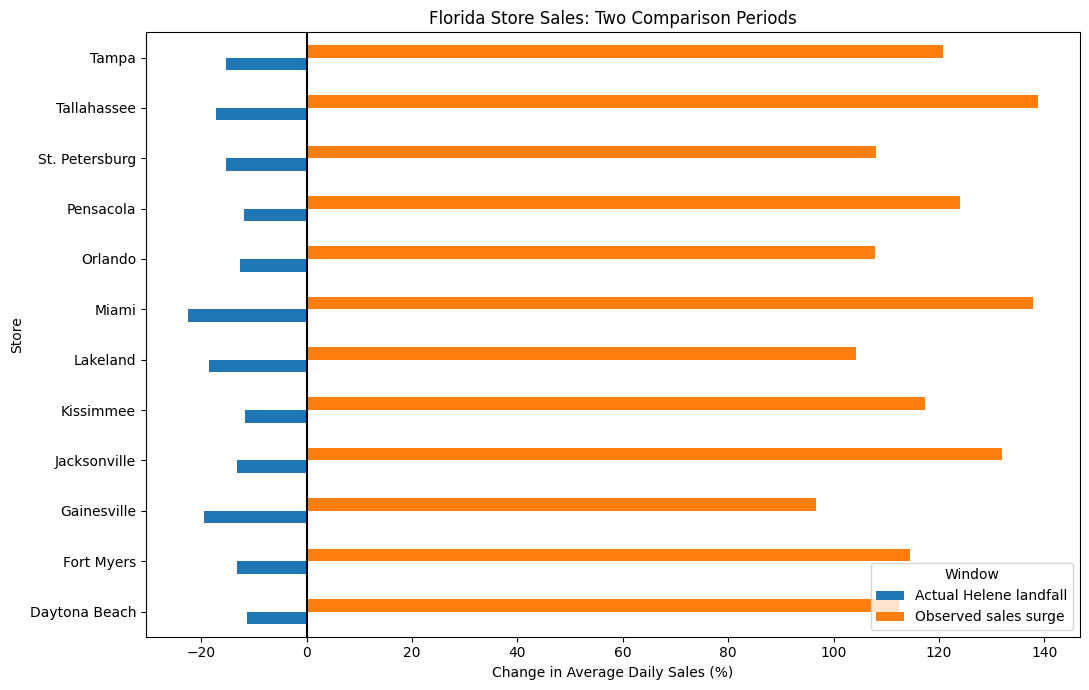

In [26]:
# Q4: Compare actual landfall and observed sales surge

q4_windows = {
    "Actual Helene landfall": (
        "2024-09-01", "2024-09-08",
        "2024-09-19", "2024-09-25"
    ),
    "Observed sales surge": (
        "2024-09-01", "2024-09-04",
        "2024-09-07", "2024-09-13"
    )
}

all_dates = pd.date_range("2024-09-01", "2024-09-30")
store_ids = stores["store_id"].dropna().unique()

daily_store_full = (
    daily_store.set_index(["store_id", "date"])["quantity"]
    .reindex(
        pd.MultiIndex.from_product(
            [store_ids, all_dates],
            names=["store_id", "date"]
        ),
        fill_value=0
    )
    .unstack("date")
)

comparison_results = []

for name, (b1, b2, s1, s2) in q4_windows.items():
    baseline = daily_store_full.loc[:, b1:b2].mean(axis=1)
    surge = daily_store_full.loc[:, s1:s2].mean(axis=1)

    result = pd.DataFrame({
        "store_id": baseline.index,
        "Baseline Avg": baseline.values,
        "Comparison Avg": surge.values
    })

    result["Surge Multiple"] = (
        result["Comparison Avg"]
        / result["Baseline Avg"].replace(0, np.nan)
    )

    result["Percentage Change"] = (
        result["Surge Multiple"] - 1
    ) * 100

    result["Window"] = name
    comparison_results.append(result)

q4_both = pd.concat(comparison_results, ignore_index=True)

q4_both = q4_both.merge(
    stores[["store_id", "city", "region"]],
    on="store_id",
    how="left",
    validate="many_to_one"
)

display(
    q4_both.sort_values(
        ["Window", "Percentage Change"],
        ascending=[True, False]
    ).round(2)
)

# Visualize both periods
chart_data = q4_both.pivot(
    index="city",
    columns="Window",
    values="Percentage Change"
)

chart_data.plot(kind="barh", figsize=(11, 7))

plt.axvline(0, color="black")
plt.title("Florida Store Sales: Two Comparison Periods")
plt.xlabel("Change in Average Daily Sales (%)")
plt.ylabel("Store")
plt.tight_layout()
plt.show()


Actual Helene landfall
Distance-sales correlation: -0.172
Stores analyzed: 12


,city,distance_miles,Surge Multiple,Percentage Change
10,Tallahassee,46.03,0.83,-17.17
0,Gainesville,85.87,0.80,-19.52
7,Jacksonville,124.26,0.87,-13.27
1,Tampa,160.29,0.85,-15.28
8,St. Petersburg,167.04,0.85,-15.28
2,Daytona Beach,169.82,0.89,-11.30
5,Lakeland,171.84,0.81,-18.55
3,Orlando,172.52,0.87,-12.57
4,Kissimmee,181.83,0.88,-11.80
11,Pensacola,211.99,0.88,-11.96


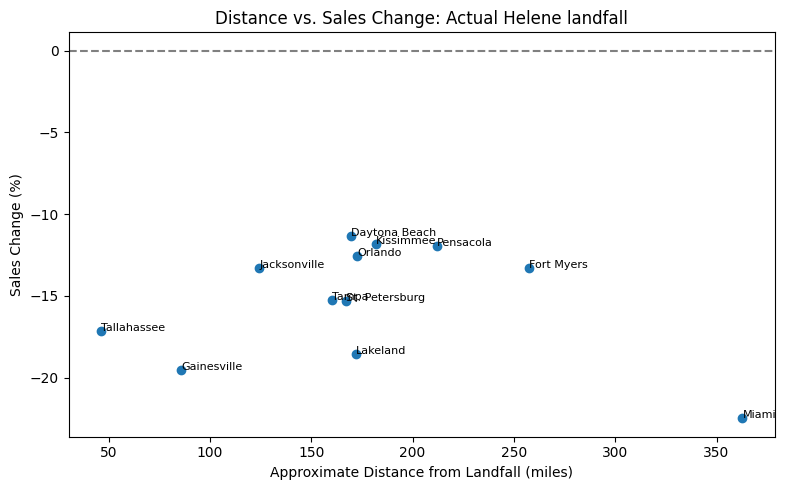


Observed sales surge
Distance-sales correlation: 0.196
Stores analyzed: 12


,city,distance_miles,Surge Multiple,Percentage Change
22,Tallahassee,46.03,2.39,138.73
12,Gainesville,85.87,1.97,96.63
19,Jacksonville,124.26,2.32,132.02
13,Tampa,160.29,2.21,120.77
20,St. Petersburg,167.04,2.08,108.11
14,Daytona Beach,169.82,2.13,112.50
17,Lakeland,171.84,2.04,104.31
15,Orlando,172.52,2.08,107.82
16,Kissimmee,181.83,2.17,117.30
23,Pensacola,211.99,2.24,123.93


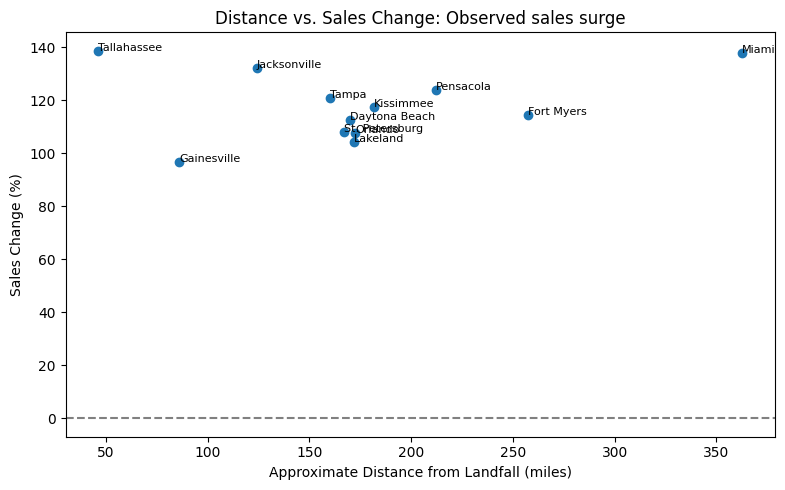

In [27]:
# Q4: Geographic distance and sales surge comparison

# Fill missing Tallahassee coordinates
mask = (
    stores["store_id"].eq("FL-619")
    & stores["latitude"].isna()
    & stores["longitude"].isna()
)

stores.loc[mask, "latitude"] = 30.4383
stores.loc[mask, "longitude"] = -84.2807

# Approximate Helene landfall coordinates
landfall_lat = 30.0
landfall_lon = -83.7

# Haversine distance in miles
lat1 = np.radians(stores["latitude"].astype(float))
lon1 = np.radians(stores["longitude"].astype(float))
lat2 = np.radians(landfall_lat)
lon2 = np.radians(landfall_lon)

a = (
    np.sin((lat2 - lat1) / 2) ** 2
    + np.cos(lat1) * np.cos(lat2)
    * np.sin((lon2 - lon1) / 2) ** 2
)

stores["distance_miles"] = (
    3958.8 * 2 * np.arcsin(np.sqrt(a.clip(0, 1)))
)

geo_results = q4_both.merge(
    stores[["store_id", "distance_miles"]],
    on="store_id",
    how="left",
    validate="many_to_one"
)

for name, group in geo_results.groupby("Window"):
    valid = group.dropna(
        subset=["distance_miles", "Percentage Change"]
    )

    r = valid["distance_miles"].corr(
        valid["Percentage Change"]
    )

    print(f"\n{name}")
    print(f"Distance-sales correlation: {r:.3f}")
    print(f"Stores analyzed: {len(valid)}")

    display(
        valid[
            ["city", "distance_miles",
             "Surge Multiple", "Percentage Change"]
        ].sort_values("distance_miles").round(2)
    )

    plt.figure(figsize=(8, 5))
    plt.scatter(
        valid["distance_miles"],
        valid["Percentage Change"]
    )

    for _, row in valid.iterrows():
        plt.annotate(
            row["city"],
            (row["distance_miles"],
             row["Percentage Change"]),
            fontsize=8
        )

    plt.title(f"Distance vs. Sales Change: {name}")
    plt.xlabel("Approximate Distance from Landfall (miles)")
    plt.ylabel("Sales Change (%)")
    plt.axhline(0, color="gray", linestyle="--")
    plt.tight_layout()
    plt.show()

We compared store-level purchasing patterns during both the seven days preceding Hurricane Helene's actual landfall and the earlier observed sales surge.

The analysis examines whether stores closer to the hurricane's landfall experienced larger increases in demand. We also compared the timing and magnitude of sales changes to identify potential outliers.

Our results suggest that distance from the landfall location was not a strong predictor of sales changes. However, the two periods produced different patterns, reinforcing the importance of distinguishing the observed sales surge from the actual hurricane timeline.

Because the analysis includes only 12 stores and uses straight-line distance from a single landfall point, these results should be interpreted cautiously.

#Question 5


The board games/entertainment category shows a +250% sales increase. Using the SQLite inventory and sales database, investigate whether this is a genuine demand signal or a data artifact (e.g., SKU miscoding, category lumping, inventory reporting lag). Present your evidence and make a recommendation: should Walmart stock extra board games for the next storm?


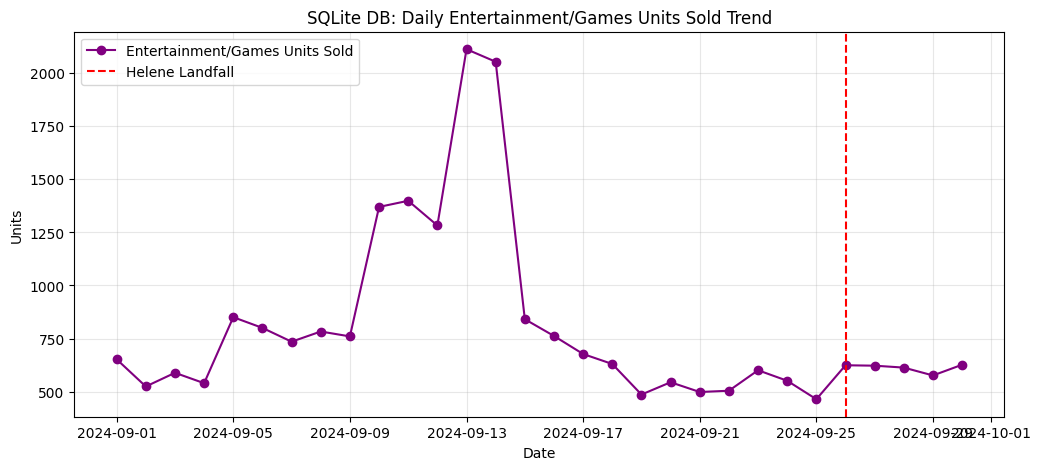

In [28]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# Connect to the SQLite database
db_path = repo_path / "data" / "inventory_and_sales.db"
conn = sqlite3.connect(str(db_path))

# Query the tables
df_summary = pd.read_sql_query("SELECT * FROM daily_sales_summary;", conn)
df_inventory = pd.read_sql_query("SELECT * FROM inventory_levels;", conn)

# Convert date strings to datetime objects
if 'date' in df_summary.columns:
    df_summary['date'] = pd.to_datetime(df_summary['date'].astype(str), format='mixed')
if 'date' in df_inventory.columns:
    df_inventory['date'] = pd.to_datetime(df_inventory['date'].astype(str), format='mixed')

# Standardize categories to uppercase for comparison
if 'category' in df_summary.columns:
    df_summary['category'] = df_summary['category'].str.upper().str.strip()

# Filter for entertainment/board game products
game_sales = df_summary[df_summary['category'].str.contains('GAMES|ENTERTAINMENT', case=False, na=False)].copy()

# Plot trends from SQLite database
if not game_sales.empty:
    daily_sales = game_sales.groupby('date')['total_units'].sum()

    plt.figure(figsize=(12, 5))
    plt.plot(daily_sales.index, daily_sales.values, marker='o', color='purple', label='Entertainment/Games Units Sold')
    plt.axvline(pd.Timestamp("2024-09-26"), color='red', linestyle='--', label='Helene Landfall')
    plt.title("SQLite DB: Daily Entertainment/Games Units Sold Trend")
    plt.xlabel("Date")
    plt.ylabel("Units")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()
else:
    print("\nNo specific entertainment transactions found in daily_sales_summary.")

conn.close()

In [29]:
ent = df_summary[df_summary.category=="ENTERTAINMENT"].groupby("date")["total_units"].sum()
print(ent["2024-09-07":"2024-09-13"].mean() / ent["2024-09-01":"2024-09-04"].mean())  # ~2.09x

inv = df_inventory.assign(sku=df_inventory.sku.str.strip().str.upper())
groups = {"games": ["BG-MONO","MONOPOLY-01","GAME-MONO","CARDS-01","PLAYCARD-STD"],
          "water": ["WTR-24","WATER24PK","WTR_24PK"], "batteries": ["BATT-100","BAT-AA4","BATT_AA_4PK"]}
for g, skus in groups.items():
    m = inv[inv.sku.isin(skus)].groupby("date")["units_on_hand"].mean()
    print(g, round(m["2024-09-10"] / m["2024-09-01":"2024-09-04"].mean(), 2))

2.093874007936508
games 0.24
water 0.2
batteries 0.23


In [30]:
# Q5: Validate Entertainment SKUs and timestamps

ent = clean_df[
    clean_df["category"] == "ENTERTAINMENT"
].copy()

print("Entertainment SKUs:")
print(sorted(ent["sku"].unique()))

essential_products = [
    "BOTTLED_WATER",
    "AA_BATTERIES",
    "LED_FLASHLIGHT",
    "EMERGENCY_CANDLES",
    "FIRST_AID_KIT"
]

miscoded = ent[
    ent["canonical_product"].isin(essential_products)
]

print("\nEmergency products classified as Entertainment:",
      len(miscoded))

print("\nEntertainment transaction count:", len(ent))
print("Distinct timestamps:", ent["timestamp"].nunique())
print("Maximum transactions sharing one timestamp:",
      ent["timestamp"].value_counts().max())

Entertainment SKUs:
['BG-MONO', 'CARDS-01', 'GAME-MONO', 'MONOPOLY-01', 'PLAYCARD-STD']

Emergency products classified as Entertainment: 0

Entertainment transaction count: 2435
Distinct timestamps: 2426
Maximum transactions sharing one timestamp: 2


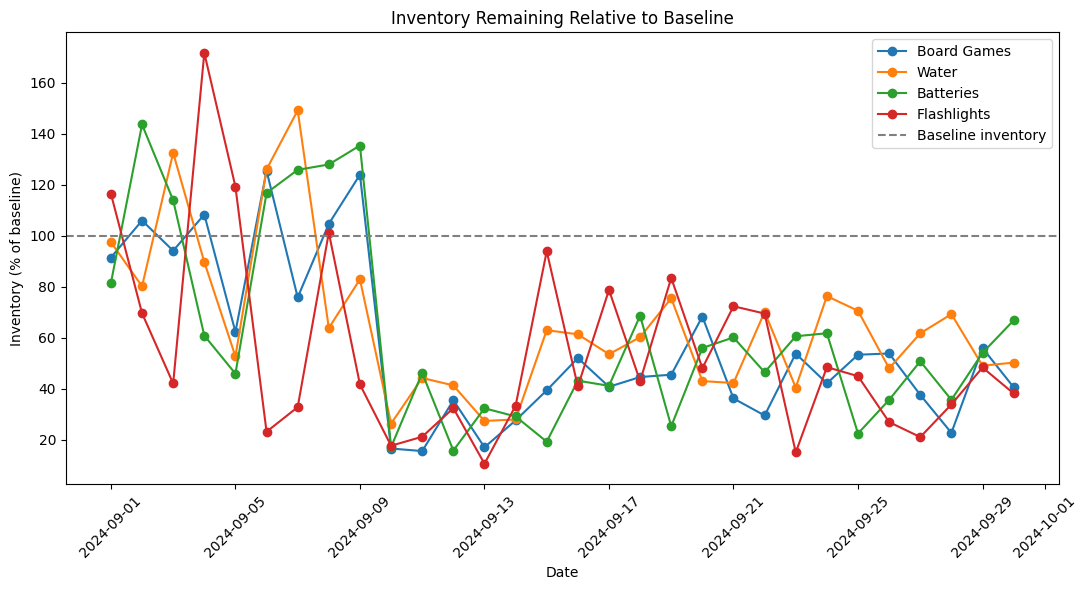

In [31]:
# Q5: Inventory levels relative to September 1-4 baseline

inventory = df_inventory.copy()
inventory["date"] = pd.to_datetime(inventory["date"])
inventory["sku"] = inventory["sku"].astype(str).str.strip().str.upper()

groups = {
    "Board Games": ["BG-MONO", "MONOPOLY-01", "GAME-MONO",
                    "PLAYCARD-STD", "CARDS-01"],
    "Water": ["WTR-24", "WATER24PK", "WTR_24PK"],
    "Batteries": ["BATT-100", "BAT-AA4", "BATT_AA_4PK"],
    "Flashlights": ["FLASH-01", "LED-FLASH"]
}

plt.figure(figsize=(11, 6))

for name, skus in groups.items():
    subset = inventory[inventory["sku"].isin(skus)]

    daily_stock = (
        subset.groupby("date")["units_on_hand"]
        .sum()
        .sort_index()
    )

    baseline = daily_stock.loc[
        "2024-09-01":"2024-09-04"
    ].mean()

    if baseline > 0:
        relative_stock = daily_stock / baseline * 100
        plt.plot(
            relative_stock.index,
            relative_stock.values,
            marker="o",
            label=name
        )

plt.axhline(100, color="gray", linestyle="--",
            label="Baseline inventory")

plt.title("Inventory Remaining Relative to Baseline")
plt.xlabel("Date")
plt.ylabel("Inventory (% of baseline)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

### Question 5: Findings and Recommendation

Our analysis suggests that the increase in board game sales represents a genuine, although relatively modest, demand surge rather than a data artifact. Entertainment sales increased to approximately 2.1 times baseline levels during the surge period.

We also examined inventory records and SKU classifications. Board game inventory declined during the surge, similarly to emergency essentials such as bottled water, batteries, and flashlights. Additionally, the Entertainment category did not contain incorrectly classified emergency products, and transaction timestamps did not show evidence of widespread batch uploads.

Based on these findings, we recommend that Walmart prioritize emergency essentials while considering a modest increase in board game inventory ahead of future storms. Although board games experienced increased demand, their surge was smaller than that of several essential products, making them a secondary inventory priority.